# RSNA Knee Abnormality Detection: обучение на Mac (MPS)

Вторая версия пайплайна, переписанная по сравнению с `01_baseline_dinov2.ipynb`. Этот ноутбук только
**обучает модель на Mac** через MPS (видеокарта Apple Silicon). Картинки он не читает из DICOM, а берёт
готовый кэш на ~15 ГБ из папки `data/`.

## Как устроен весь проект

| Ноутбук | Где | Что делает |
|---|---|---|
| `03_build_cache_kaggle.ipynb` | Kaggle, CPU | читает 570 ГБ DICOM и сохраняет кэш ~15 ГБ как датасет |
| **`02_report_labels_mil.ipynb`** | **Mac, MPS** | **учит модель на кэше, пишет веса в `outputs/weights`** |
| `04_kaggle_submission.ipynb` | Kaggle, GPU | берёт веса, читает test и делает `submission.csv` |

## Перед запуском

1. Положить в `data/` рядом с этим ноутбуком два файла:
   - `cache_train.npy` (~15 ГБ): кэш картинок из `03_build_cache_kaggle.ipynb`;
   - `train.csv` (~6 МБ): со страницы соревнования на Kaggle (вкладка Data). В нём метки и тексты
     заключений, а в пикселях кэша их нет.

   Всё остальное (порядок исследований, какие серии заполнены, настройки кэша) ноутбук вычисляет сам, раздел 2.
2. Открыть ноутбук в VS Code так, чтобы рабочей папкой была `rsna-knee-abnormality-detection`.
3. Run All. Для первого раза оставьте `FOLDS_TO_RUN = [0]` и посмотрите на `gold` в логе.

## Почему первая версия стояла на 0.55

В `train.csv` 12 меток заполнены только у **58 из 4407** исследований, у остальных `NaN`.
`np.nan_to_num(labels, nan=0.0)` превращал 98.7% данных в «пациент полностью здоров», модель училась
отвечать «0», а метрика была шумом. Настоящий источник меток - текст заключения радиолога (`Report`).

## Схема

```
Report ──> extract() ──> Y (мягкие метки 0.04…0.95) + W (вес = уверенность экстрактора)
data/cache_train.npy: [исследование, 6 серий, 12 срезов, 224, 224]
каждые 3 соседних среза = 1 картинка ──> DINOv2 ──> вектор
все картинки исследования ──> трансформер ──> своё внимание для каждой из 12 патологий ──> 12 логитов
лосс: BCE × W + ranking; OneCycleLR; EMA; 4 фолда по hash(Report)
```

In [10]:
import os 
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "4")

import gc 
import math 
import time 
import json
import hashlib 
import textwrap 
import warnings
from copy import deepcopy 
from pathlib import Path 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import torch 
import torch.nn as nn
import torch.nn.functional as F 
import timm 
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
T0 = time.time()

def log(msg):
    print(f"[{time.time() - T0:7.1f}s] {msg}", flush=True)

try:
    display 
except NameError:
    display = print 

# Устройство: видеокарта Apple Silicon через MPS, иначе процессор
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
log(f"устройство: {DEV}, torch {torch.__version__}, timm {timm.__version__}")

[    0.0s] устройство: mps, torch 2.8.0, timm 1.0.30


## 0. Конфиг

Настройки подготовки картинок (`IMG`, `CROP_MM`, `K_WIN`, `WIN_BAND`) здесь не задаются: они читаются из
`rsna_cache_meta.json`, с которыми собран кэш. Меняйте **одну** ручку за раз и смотрите на `gold`.

In [11]:
SEED = 2026

# ---------------- Папки ----------------
# Ноутбук запускается из папки rsna-knee-abnormality-detection.
DATA_DIR = Path.cwd() / "data"            # здесь лежат cache_train.npy и train.csv
OUT_DIR = Path.cwd() / "outputs"          # сюда пишутся веса фолдов
WEIGHTS_DIR = OUT_DIR / "weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
for _name in ("cache_train.npy", "train.csv"):
    assert (DATA_DIR / _name).is_file(), f"Нет файла {DATA_DIR / _name}"

# ---------------- Как собран кэш (должно совпадать с 03_build_cache_kaggle.ipynb) ----------------
# IMG и K_WIN ниже прочитаются из формы массива. Эти три настройки по пикселям не определить,
# поэтому они записаны здесь. Они же сохраняются в каждый файл весов, и 04_kaggle_submission.ipynb
# готовит test ровно так же.
CROP_MM = 140.0            # квадрат 140x140 мм вокруг центра снимка, потом ресайз
WIN_BAND = (0.08, 0.92)    # окна стоят от 8% до 92% стека срезов
FILL_MISSING_SLOTS = True  # нет серии с fat-sat -> взята серия той же плоскости без него (и наоборот)
SLOTS = [  # (имя, плоскость, Fat_Suppression) - порядок слотов во второй оси кэша
    ("SAG_FS", "Sagittal", 1), ("COR_FS", "Coronal", 1), ("AX_FS", "Axial", 1),
    ("SAG_NOFS", "Sagittal", 0), ("COR_NOFS", "Coronal", 0), ("AX_NOFS", "Axial", 0),
]

# ---------------- Энкодер (2D-сеть, которая смотрит на одну картинку) ----------------
BACKBONE = "vit_small_patch14_dinov2.lvd142m"   # DINOv2 ViT-S, 22M параметров
WEIGHTS_PATH = None        # путь к .pth с весами; None: timm скачает их из интернета сам
UNFREEZE_LAST = 6          # сколько последних блоков ViT учится (из 12). Ранние блоки - общие
                           # «детекторы краёв»: данных мало, испортить их легко

# ---------------- Метки ----------------
GOLD_IN_TRAIN = False      # False: 58 размеченных НЕ участвуют в обучении, на них честная проверка

# ---------------- Модель (голова над энкодером) ----------------
HIDDEN = 256               # размер векторов в голове
TF_DEPTH = 1               # слоёв трансформера, через которые окна «переговариваются» (0 = выключить)

# ---------------- Обучение ----------------
N_FOLDS = 4                # на сколько частей делим данные (по хэшу текста заключения, раздел 4)
FOLDS_TO_RUN = [0]         # какие части учить: каждая = отдельная модель. Итоговый вариант: [0, 1, 2, 3]
EPOCHS = 10
BATCH_STUDIES = 8          # исследований в батче
K_TRAIN = 2                # окон на серию в каждом шаге обучения (случайные из K_WIN): быстрее и работает
                           # как аугментация. На проверке берутся все окна
LR_BACKBONE = 8e-6         # энкодер только «подстраиваем»: большой LR разрушит предобучение
LR_HEAD = 5e-4             # голова учится с нуля, ей нужен LR намного больше
WEIGHT_DECAY = 0.02
PCT_START = 0.15           # первые 15% шагов LR плавно растёт (разогрев), потом падает до нуля
EMA_DECAY = 0.997          # «скользящее среднее» весов, сглаживает шум (0 = выключить)
RANK_LOSS_W = 0.05         # вес ранжирующего лосса (напрямую тянет AUC вверх)
RANK_POS, RANK_NEG = 0.60, 0.40   # мягкая метка > 0.6 - «есть», < 0.4 - «нет» (для ranking loss)
USE_AMP = DEV.type == "mps"       # смешанная точность float16: на MPS шаг примерно в 1.5 раза быстрее
AMP_DTYPE = torch.float16

# Аугментации: только то, что не меняет смысл метки (подробно в разделе 6)
AUG_ROT_DEG, AUG_SCALE, AUG_SHIFT = 10.0, 0.10, 0.06   # поворот ±10°, зум до +10%, сдвиг ±6%
AUG_GAMMA, AUG_GAIN = 0.25, 0.10                       # контраст (гамма) и яркость ±10%
MIRROR_P = 0.5             # с вероятностью 50% «зеркалим колено» (левое <-> правое)
TTA_MIRROR = True          # на проверке усредняем обычный и зеркальный вид
EVAL_BATCH = 4             # исследований за раз при предсказании

TARGETS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
           "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
           "Contusion", "Fracture"]


def seed_everything(seed):
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEV.type == "mps":
        torch.mps.manual_seed(seed)


def empty_device_cache():
    if DEV.type == "mps":
        torch.mps.empty_cache()


seed_everything(SEED)
log(f"данные: {DATA_DIR}, веса фолдов: {WEIGHTS_DIR}")

[    0.0s] данные: /Users/admin/Desktop/kaggle-deep-learning/rsna-knee-abnormality-detection/data, веса фолдов: /Users/admin/Desktop/kaggle-deep-learning/rsna-knee-abnormality-detection/outputs/weights


## 1. Таблицы

### 1.1 `train.csv`: одна строка = одно исследование

Смотрите на колонки целей: сколько в них **пустых** значений. Это и есть главный вывод.

In [12]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
print("размер:", train_df.shape, "  колонки:", list(train_df.columns))
display(train_df.drop(columns=["Report"]).head(5))

gold_mask_df = train_df[TARGETS].notna().all(axis=1)      # True, если все 12 меток заполнены
print(f"\n Исследований с РУЧНОЙ разметкой всех 12 меток: {int(gold_mask_df.sum())} из {len(train_df)}")
print(f"   У остальных {int((~gold_mask_df).sum())} метки пустые (NaN). В v1 они стали нулями - отсюда 0.55.\n")

cnt = pd.DataFrame({"заполнено": train_df[TARGETS].notna().sum(),
                    "пусто (NaN)": train_df[TARGETS].isna().sum(),
                    "доля «есть» среди размеченных": train_df.loc[gold_mask_df, TARGETS].mean().round(2)})
display(cnt)

размер: (4407, 14)   колонки: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



 Исследований с РУЧНОЙ разметкой всех 12 меток: 58 из 4407
   У остальных 4349 метки пустые (NaN). В v1 они стали нулями - отсюда 0.55.



,заполнено,пусто (NaN),доля «есть» среди размеченных
ACL,58,4349,0.41
MCL,58,4349,0.16
Medial Meniscus,58,4349,0.45
Lateral Meniscus,58,4349,0.40
Medial OA,58,4349,0.26
Lateral OA,58,4349,0.19
PF OA,58,4349,0.36
Effusion,58,4349,0.60
Synovitis,58,4349,0.47
Baker's,58,4349,0.21


### 1.3 Тексты заключений (`Report`) - настоящий источник меток

Заключения на разных языках (английский, испанский, турецкий, греческий, болгарский…).
Именно из них в разделе 3 мы сделаем метки для всех 4407 исследований.

In [13]:
rep = train_df["Report"].fillna("")
print(f"длина заключения в символах: медиана {int(rep.str.len().median())}, "
      f"min {rep.str.len().min()}, max {rep.str.len().max()}\n")

print("Начала 12 случайных заключений (видно, какие языки):")
for t in rep.sample(12, random_state=0):
    print("  •", t.replace("\n", " ")[:110])

print("\n" + "=" * 100)
ex = train_df[gold_mask_df].iloc[0]
print("Пример ПОЛНОГО заключения у размеченного исследования и его ручные метки:\n")
print(textwrap.fill(ex["Report"][:1500], 110))
print("\nручные метки:", {t: int(ex[t]) for t in TARGETS})

длина заключения в символах: медиана 977, min 52, max 4743

Начала 12 случайных заключений (видно, какие языки):
  • ΤΕΧΝΙΚΗ: Η εξέταση πραγµατοποιήθηκε µε ακολουθίες PD µε καταστολή του σήµατος του λίπους, Τ1 και Τ2*. ΕΥΡΗΜΑΤΑ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs anterior ve posterior ho
  • MRI ∆ΕΞΙΟΥ ΓΟΝΑΤΟΣ ΤΕΧΝΙΚΗ Η εξέταση έγινε µε ακολουθίες παλµών Τ1 και πυκνότητας πρωτονίων µε καταστολή του σ
  • SAĞ DİZ MRG. Tetkik protokolü: Çok düzlemli, çok sekanslı. Bulgular: Lateral menisküs normaldir.  Medial menis
  • Antecedentes Clínicos: Síndrome meniscal medial. Hallazgos: No hay alteraciones de señal significativas de la 
  • FINDINGS:  Fluid: No joint effusion. No popliteal cyst. Small popliteal ganglion cyst.  Medial compartment (me
  • No evidence of knee effusion. Normal medial and lateral menisci. No evidence of tears.  Normal ACL, PCL, MCL a
  • Lig. iliotibiale postoperativ zunehmend verdickt von zuletzt 3 auf 6 mm (5/14)

### 1.4 `train_series.csv`: какие серии есть в каждом исследовании

Одно исследование = **несколько серий**: снимки в разных плоскостях
(сагиттальная - «сбоку», корональная - «спереди», аксиальная - «сверху»)
и в разных режимах (`Fat_Suppression` = 1 -> жир подавлен, отёки и жидкость яркие).

Файл `train_series.csv` для обучения не нужен. Если его нет в `data/`, ячейка пропускается.

In [14]:
if not (DATA_DIR / "train_series.csv").is_file():
    print("train_series.csv нет в data/: таблица серий пропущена (для обучения она не нужна)")
else:
    train_series = pd.read_csv(DATA_DIR / "train_series.csv")
    print("размер:", train_series.shape, "  колонки:", list(train_series.columns))
    display(train_series.head(6))

    print("\nСколько серий каждой плоскости, с подавлением жира (1) и без (0):")
    display(pd.crosstab(train_series["Anatomical_Plane"], train_series["Fat_Suppression"]))
    if "Fluid_Sensitive" in train_series.columns:
        same = (train_series["Fat_Suppression"] == train_series["Fluid_Sensitive"]).mean()
        print(f"Fat_Suppression совпадает с Fluid_Sensitive в {same:.1%} строк (то есть это по сути один флаг)")

    per_study = train_series.groupby("StudyInstanceUID").size()
    print(f"\nсерий на исследование: в среднем {per_study.mean():.1f}, min {per_study.min()}, max {per_study.max()}")
    combo = (train_series.assign(k=train_series["Anatomical_Plane"].str[:3] + train_series["Fat_Suppression"].map({1: "+FS", 0: ""}))
             .groupby("StudyInstanceUID")["k"].apply(lambda s: " ".join(sorted(s))))
    print("\nСамые частые наборы серий в исследовании:")
    display(combo.value_counts().head(8).rename("исследований").to_frame())

train_series.csv нет в data/: таблица серий пропущена (для обучения она не нужна)


## 2. Кэш картинок

Кэш собран ноутбуком `03_build_cache_kaggle.ipynb` из DICOM. Это один массив
`[исследование, слот, срез, высота, ширина]`, где:

- **слот**: до 6 серий исследования (три плоскости, с подавлением жира и без);
- **срез**: 4 окна по 3 соседних среза = 12 срезов, окна стоят от 8% до 92% стека;
- каждый срез уже приведён к одной ориентации, обрезан до 140 мм и уменьшен до `IMG` пикселей.

`cache_train.npy` весит ~15 ГБ, а памяти на Mac 24 ГБ, поэтому он открывается **с диска** через
`np.load(..., mmap_mode="r")`: в память читается только тот батч, который нужен сейчас.

Кроме пикселей модели нужны ещё три вещи. Их не нужно скачивать, они вычисляются здесь:

| Что | Зачем | Как получаем |
|---|---|---|
| `ST_TR`: какое исследование в какой строке | связать картинки с метками из `train.csv` | 03 кладёт исследования в кэш в порядке сортировки ID, значит строки идут как `sorted(train.csv)` |
| `MTR`: какие слоты заполнены | пустые слоты не идут в модель | пустой слот в кэше целиком из нулей; если в его срезах есть ненулевые пиксели, он заполнен |
| `PTR`: где в стеке стоит каждое окно | подсказка модели «это край или середина серии» | окна расставлены равномерно в полосе `WIN_BAND`: `[0.08, 0.36, 0.64, 0.92]` |

In [15]:
CTR = np.load(DATA_DIR / "cache_train.npy", mmap_mode="r")   # с диска, без загрузки в память

# --- форма массива сама говорит о части настроек ---
N_STUDY, N_SLOT, N_SLICE, IMG, _ = CTR.shape
K_WIN = N_SLICE // 3                       # 12 срезов = 4 окна по 3 соседних среза
assert N_SLOT == len(SLOTS) and N_SLICE == K_WIN * 3 and CTR.shape[3] == CTR.shape[4], CTR.shape
SAG_SLOTS = [k for k, (_, plane, _) in enumerate(SLOTS) if plane == "Sagittal"]   # для зеркала колена

# --- ST_TR: какое исследование в какой строке кэша ---
# 03 собирает кэш по исследованиям в порядке sorted(ID). У всех 4407 исследований есть хотя бы
# одна серия, поэтому строк в кэше столько же, сколько в train.csv, и порядок совпадает.
ST_TR = sorted(train_df["StudyInstanceUID"].astype(str))
assert len(ST_TR) == N_STUDY, (
    f"в кэше {N_STUDY} строк, а в train.csv {len(ST_TR)} исследований: кэш собран не из этого train.csv")

# --- MTR: какие слоты заполнены ---
# Пустой слот 03 оставляет нулевым. Смотрим на центральный срез каждого окна (4 среза из 12):
# если там есть хоть один ненулевой пиксель, слот заполнен. Читаем кэш кусками по 256 исследований,
# чтобы не держать в памяти больше ~0.6 ГБ за раз.
t0 = time.time()
MTR = np.zeros((N_STUDY, N_SLOT), np.float32)
for a in range(0, N_STUDY, 256):
    centre = np.asarray(CTR[a:a + 256, :, 1::3])          # [кусок, слот, 4 центральных среза, IMG, IMG]
    MTR[a:a + 256] = centre.reshape(*centre.shape[:2], -1).max(-1) > 0
log(f"маска слотов посчитана за {time.time() - t0:.0f}s")

# --- PTR: где в стеке стоит каждое окно ---
# 03 ставит центры окон равномерно в полосе WIN_BAND. Точная доля зависит от числа срезов в серии
# (округление до целого среза), но разница - сотые доли. В 04_kaggle_submission.ipynb используются
# те же значения, поэтому обучение и сабмит видят одно и то же.
WIN_POS = np.linspace(WIN_BAND[0], WIN_BAND[1], K_WIN).astype(np.float32)
PTR = np.broadcast_to(WIN_POS, (N_STUDY, N_SLOT, K_WIN)).copy()

log(f"кэш: {CTR.shape}, {CTR.nbytes / 1024 ** 3:.1f} ГБ на диске; IMG={IMG}, K_WIN={K_WIN}, позиции окон {WIN_POS.round(2)}")
display(pd.DataFrame({"слот": [s[0] for s in SLOTS], "заполнен у доли исследований": MTR.mean(0).round(3)}))

[   25.8s] маска слотов посчитана за 26s
[   25.8s] кэш: (4407, 6, 12, 224, 224), 14.8 ГБ на диске; IMG=224, K_WIN=4, позиции окон [0.08 0.36 0.64 0.92]


,слот,заполнен у доли исследований
0,SAG_FS,1.0
1,COR_FS,1.0
2,AX_FS,1.0
3,SAG_NOFS,1.0
4,COR_NOFS,1.0
5,AX_NOFS,1.0


### 2.1 Проверка глазами

Строка = слот (серия), столбец = центральный срез одного из 4 окон. Должно быть видно колено в разных
плоскостях, в одной ориентации и с нормальным контрастом. Чёрные клетки допустимы только при `mask=0`.

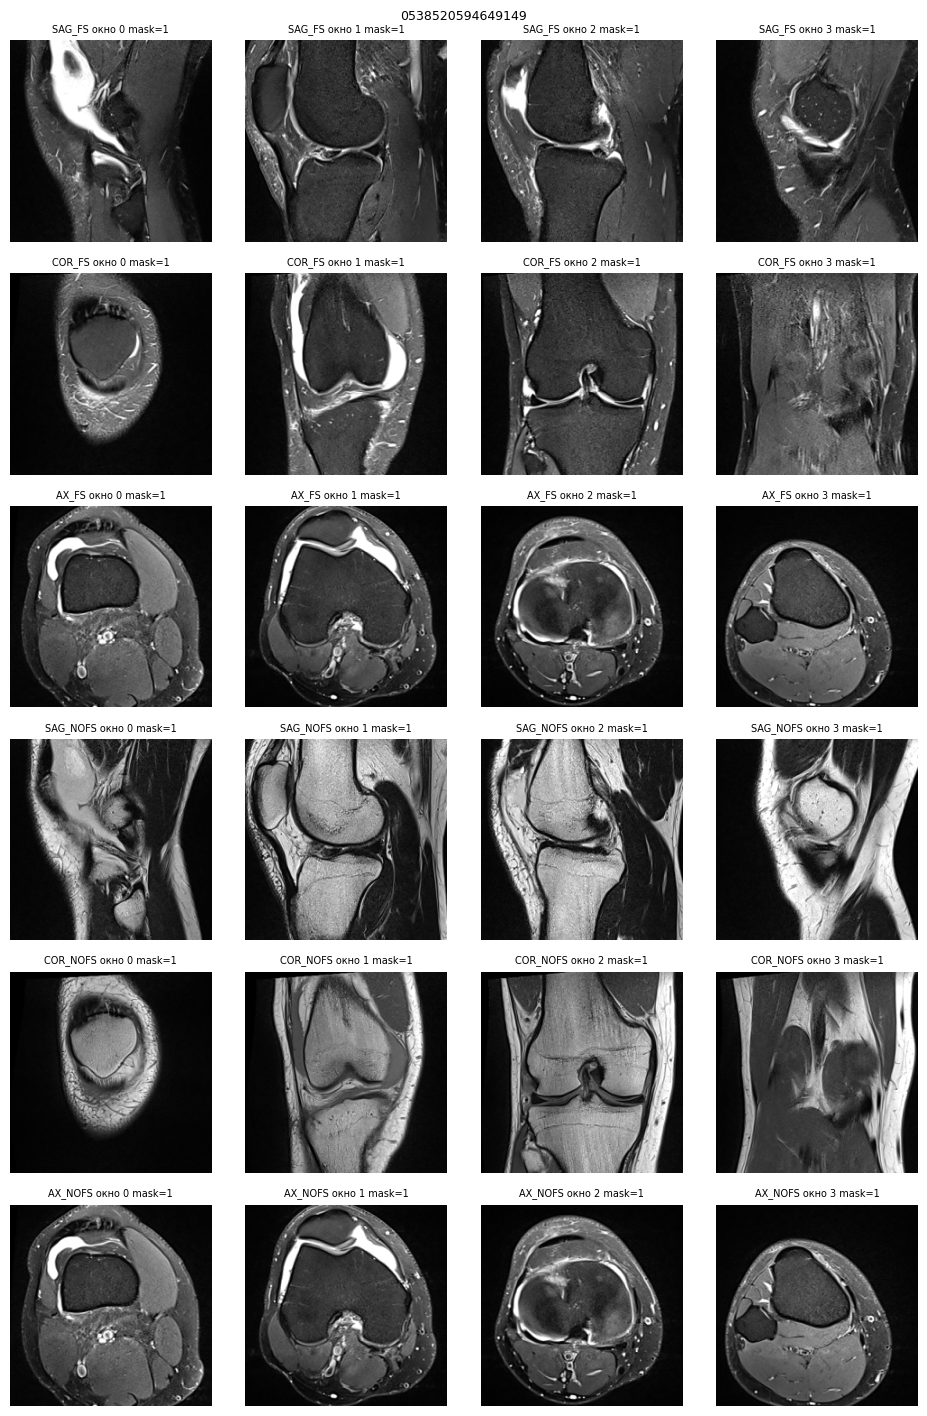

In [16]:
def show_cached_study(i):
    fig, axes = plt.subplots(N_SLOT, K_WIN, figsize=(2.4 * K_WIN, 2.4 * N_SLOT))
    for s in range(N_SLOT):
        for j in range(K_WIN):
            axes[s, j].imshow(CTR[i, s, j * 3 + 1], cmap="gray")
            axes[s, j].set_title(f"{SLOTS[s][0]} окно {j} mask={MTR[i, s]:.0f}", fontsize=7)
            axes[s, j].axis("off")
    plt.suptitle(ST_TR[i][-16:], fontsize=9)
    plt.tight_layout(); plt.show()


show_cached_study(ST_TR.index(train_df.loc[gold_mask_df, "StudyInstanceUID"].iloc[0]))

## 3. Метки из текстов заключений

### Идея
Для каждой из 12 патологий экстрактор на регулярных выражениях читает заключение по фразам и решает:
- фраза **утверждает** находку («complete tear of the ACL»);
- **отрицает** её («ACL intact», «sin derrame»);
- **сомневается** («possible tear»);
- или **молчит**.

### Шкала (мягкие метки, а не 0/1)

| что сказано | score | вес примера `W = 0.25 + 0.75·уверенность` |
|---|---|---|
| утверждение «large/marked» | до 0.95 | высокий |
| утверждение без уточнения | ~0.85 | высокий |
| «small/trace» | ~0.72 | высокий |
| сомнение | ~0.63 | средний |
| **тишина** | **0.28** | **≈0.29** (почти не влияет на обучение) |
| отрицание | 0.04-0.20 | средний/высокий |

**Почему не 0/1.** Метрика AUC смотрит только на **порядок** чисел. Радиолог в тексте и разметчик
используют разные пороги («небольшой выпот» разметчик мог пометить как 0). Мягкая шкала сохраняет
порядок «точно есть > возможно > не сказано > точно нет» и не навязывает порог.

Следующие 6 ячеек - экстрактор. Вникать в каждую регулярку не нужно. Достаточно понимать:
`extract(текст)` -> `{"ACL": 0.85, "ACL__conf": 0.7, …}`.

In [17]:
# Ячейка 1/6 экстрактора: нормализация текста и разбиение на фразы
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# Модули: re - регулярные выражения, unicodedata - работа с диакритикой (é -> e)
import re
import unicodedata

# 12 целей соревнования - в этом порядке идут колонки и в train.csv, и в submission
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]


# Таблица замен ДО перевода в нижний регистр.
# Турецкие İ/ı иначе превращаются в странные символы, и "İZLENMEZ" ≠ "izlenmez".
# Плюс немецкая ß, хорватская đ, датские ø/æ.
_PRE = str.maketrans({
    "ı": "i", "İ": "i", "I": "i", "ß": "ss", "đ": "d", "Đ": "d",
    "ø": "o", "Ø": "o", "æ": "ae", "Æ": "ae",
})


# normalize(текст) -> текст в «удобной для регулярок» форме:
# - нижний регистр, без диакритики (греческое ά -> α, é -> e);
# - MICRO SIGN µ (U+00B5) -> настоящая греческая μ (в греческих отчётах путают);
# - дефисы/слэши/подчёркивания -> пробелы, лишние пробелы схлопнуты.
def normalize(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.translate(_PRE).lower()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    # мягкий перенос (невидимый символ) - удаляем
    text = text.replace("­", "")
    text = re.sub(r"[_\-/\\]+", " ", text)
    text = re.sub(r"[ \t]+", " ", text)
    return text


# Разбиение на фразы: после . ; ! ? или по переводу строки
_SENT_SPLIT = re.compile(r"(?<=[.;!?])\s+|\n+")


# clauses(текст) -> список фраз.
# Важная хитрость: строка-заголовок вида "Fractures :" склеивается со следующей "Aucune."
# («Переломы: нет»). Если их не склеить, заголовок «Fractures» без отрицания
# прочитается как «перелом есть».
def clauses(text: str):
    norm = normalize(text)
    raw = [c.strip() for c in _SENT_SPLIT.split(norm) if c and c.strip()]

    merged = []
    for i, c in enumerate(raw):
        # Фраза кончается двоеточием и короткая (≤14 слов) -> это заголовок,
        # приклеиваем к нему следующую фразу. Сам заголовок отдельно НЕ оставляем.
        if c.endswith(":") and len(c.split()) <= 14 and i + 1 < len(raw):
            merged.append(c + " " + raw[i + 1])
        else:
            merged.append(c)
    # Длинные перечисления через запятую (>25 слов) дополнительно режем по запятым
    out = []
    for c in merged:
        out.append(c)
        if len(c.split()) > 25:
            out.extend(p.strip() for p in c.split(",") if len(p.split()) > 2)
    return out


# _rx('a', 'b', ...) -> одна скомпилированная регулярка 'a|b|...' (любой из вариантов)
def _rx(*alts: str) -> re.Pattern:
    return re.compile("|".join(alts))

In [18]:
# Ячейка 2/6 экстрактора: словари «как сказано» - отрицание, норма, сомнение, патология
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Словари «как сказано» (для всех 9 языков сразу) ===
# NEGATION - слова отрицания: no, sin, pas de, geen, kein, yok, nema, δεν, без …
# Если отрицание есть во фразе -> находка «отрицается».
NEGATION = _rx(
    # английский
    r"\bno\b", r"\bnot\b", r"\bwithout\b", r"\bnegative for\b", r"\babsence\b",
    r"\bno evidence\b", r"\bunremarkable\b", r"\bfree of\b", r"\bnone\b", r"\bnil\b",
    # испанский
    r"\bsin\b", r"\bno hay\b", r"\bausencia\b", r"\bausentes?\b",
    # французский
    r"\bpas de\b", r"\bsans\b", r"\baucune?\b", r"\babsence\b",
    # нидерландский
    r"\bgeen\b", r"\bzonder\b", r"\bniet\b",
    # немецкий
    r"\bkeine?\b", r"\bohne\b", r"\bnicht\b",
    # турецкий
    r"\byok\b", r"\byoktur\b", r"izlenmemekte", r"saptanmadi", r"\bdegil\b",
    r"gozlenmemekte", r"mevcut degil", r"eslik etmiyor", r"\bizlenmedi\b",
    # хорватский / сербский / боснийский
    r"\bnema\b", r"\bbez\b", r"\bnisu\b", r"\bnije\b",
    # греческий (ударения уже сняты normalize)
    r"\bδεν\b", r"\bχωρις\b", r"ουδεν",
    # болгарский / русский
    r"\bбез\b", r"\bне\b", r"липсва", r"\bняма\b",
)

# NORMALITY - «норма»: normal, intact, preserved, conservado, φυσιολογικ …
# «Связки в норме» = доказательство отсутствия находки (а не просто молчание).
NORMALITY = _rx(
    r"\bnormal", r"\bintact\b", r"\bpreserved\b", r"\bwithin normal limits\b",
    r"limites normales", r"\bconservad", r"\bintegr", r"\bnormales\b",
    r"\bdoga(l|ll)\b", r"korunmus", r"\bnormaldir\b", r"olagan",
    r"\buredn", r"\bocuvan", r"\bodrzan", r"\bintakt",
    r"φυσιολογικ", r"ακεραι",
    r"unauffallig", r"regelrecht", r"\bintakt\b",
    r"нормал", r"запазен", r"съхранен", r"\bбез особености\b",
    r"\bgaaf\b", r"\bnormaal\b",
)

# UNCERTAIN - сомнение: possible, suspected, cannot exclude, πιθαν …
UNCERTAIN = _rx(
    r"\bpossible\b", r"\bprobable\b", r"\bsuspicious\b", r"\bsuspected\b",
    r"cannot (be )?exclude", r"\bmay\b", r"\bquestionable\b", r"\bequivocal\b",
    r"\bposible\b", r"sin criterios categoricos", r"\bdudos",
    r"\bmuhtemel\b", r"\bolasi\b", r"\bsupheli\b", r"\bizlenim",
    r"\bmoguce\b", r"\bvjerojatno\b", r"\bsumnja\b",
    r"πιθαν", r"υποπτ",
    r"\bmoglich", r"\bverdachtig", r"\bfraglich", r"\bV\.a\.\b",
    r"\bвъзможно\b", r"\bвероятно\b", r"суспект",
    r"\bmogelijk\b", r"\bverdacht\b",
)

# === Словари патологии (используются для связок и менисков) ===
# TEAR - разрыв: tear, rupture, rotura, déchirure, Riss, yırtık, ρηξη, руптура …
TEAR = _rx(
    r"\btear", r"\btorn\b", r"\brupture", r"\bdisruption\b", r"discontinuit",
    r"\bavuls",
    r"\brotura\b", r"\broturas\b", r"\bruptura", r"\bdesgarro", r"\broto\b",
    r"\bdechirure", r"\bdechire",
    r"\bscheur", r"\bruptuur", r"gescheurd",
    r"riss(bildung|e|es)?\b", r"einriss", r"\bruptur", r"zerreiss", r"\blasion",
    r"\byirtik", r"\byirtig", r"\bkopma\b", r"butunluk kaybi", r"\brupturu\b",
    r"\bpuknuce", r"\bruptur", r"\bprekid\b", r"\bpukotin",
    r"ρηξη", r"ρηξις", r"ρηγμα",
    r"руптура", r"разкъсв", r"разрив", r"скъсв",
)

# DEGEN - дегенерация: degenerat, mucoid, fray, fissur …
DEGEN = _rx(
    r"degenerat", r"\bmucoid\b", r"\bmyxoid\b", r"\bfray", r"\bfissur",
    r"dejeneratif", r"\bmukoid\b", r"degenerativn", r"εκφυλ", r"дегенерат",
    r"\bμυξοειδ", r"\bμυξωδ",
    r"\bmuco ?ide\b", r"aufgefasert",
)

# INJURY - повреждение/отёк/сигнал: injury, sprain, edema, high signal, partial …
INJURY = _rx(
    r"\binjur", r"\bsprain", r"\blesion", r"\blasion", r"\bedema\b", r"\boedema\b",
    r"\bodem\b", r"\bedem\b", r"\bοιδημα", r"\bодем", r"\bедем", r"\bstrain\b",
    r"\bhigh signal\b", r"\bsignal alteration\b", r"\bhiperintens", r"\bhyperintens",
    r"aumento de senal", r"alteracion de senal", r"cambio de senal",
    r"\bsignalanhebung", r"\bsignalalteration", r"verhoogd signaal", r"sinyal artis",
    r"αυξημενο σημα", r"повишен сигнал",
    r"\bthicken", r"\bzadebljanje\b", r"\bverdikking\b", r"\bdistenzij",
    r"\blaksite\b", r"\blaxity\b", r"\bpartial\b", r"\bparcijaln", r"\bparcial",
    r"\bpartiel", r"\bpartiell",
)

In [19]:
# Ячейка 3/6 экстрактора: словари анатомии, остеоартрита и «самоназывающих» находок
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Анатомия: для 4 «парных» целей (ACL, MCL, медиальный/латеральный мениск) ===
# Находка засчитывается, только если во фразе есть И анатомия (этот словарь),
# И патология (TEAR/DEGEN/INJURY из прошлой ячейки).
ANAT = {
    # передняя крестообразная связка
    "ACL": _rx(
        r"anterior cruciate", r"\bacl\b",
        r"cruzado anterior", r"\blca\b",
        r"croise anterieur",
        r"voorste kruisband", r"\bvkb\b",
        r"vorderes kreuzband", r"vorderen kreuzband", r"vordere kreuzband",
        r"on capraz", r"\bocb\b",
        r"prednji krizni", r"prednjeg krizn",
        r"προσθι[οα][^ ]* χιαστ", r"προσθιου χιαστου", r"χιαστο[^ ]* συνδεσμ",
        # греческий отделяет прилагательное от существительного
        # ("χιαστοι και πλαγιοι συνδεσμοι"), поэтому основа «χιαστ» стоит отдельно
        r"\bχιαστ\w*",
        r"предна кръстна", r"предната кръстна",
        # множественное число без стороны: «крестообразные связки в норме»
        # очищает сразу обе связки - без этих форм фраза терялась
        r"cruciate ligaments", r"ligamentos cruzados", r"ligaments croises",
        r"kruisbanden", r"kreuzbander", r"capraz baglar", r"krizn[a-z]* ligament[a-z]*",
        r"χιαστοι συνδεσμ", r"χιαστων συνδεσμ", r"кръстните връзки", r"кръстни връзки",
    ),
    # медиальная коллатеральная связка
    "MCL": _rx(
        r"medial collateral", r"\bmcl\b", r"tibial collateral",
        r"colateral medial", r"colateral interno", r"\blcm\b",
        r"collateral medial", r"collateral interne",
        r"mediale collaterale", r"binnenband", r"\b(mediale|laterale) banden\b",
        r"\bcollaterale banden\b",
        r"innenband", r"mediales? kollateral",
        r"\bic yan bag", r"medial kollateral", r"\biyb\b",
        r"medijalni kolateraln", r"medijalnog kolateraln",
        r"εσω πλαγι", r"εσωτερικο πλαγι", r"\bπλαγι\w* συνδεσμ", r"\bπλαγιοι\b",
        r"медиален колатерал", r"вътрешна странична", r"\bколатерал\w*",
        # то же для коллатеральных: «cruzados y colaterales» - прилагательное отдельно
        r"\bcolaterales\b", r"\bcollateraux\b", r"\bcollateralen\b", r"\bkolateralni\b",
        r"collateral ligaments", r"ligamentos colaterales", r"ligaments collateraux",
        r"collaterale banden", r"kollateralbander", r"seitenbander", r"yan baglar",
        r"kolateraln[a-z]* ligament[a-z]*", r"πλαγιοι συνδεσμ", r"πλαγιων συνδεσμ",
        r"колатерални връзки", r"страничните връзки",
    ),
    # медиальный мениск
    "Medial Meniscus": _rx(
        r"medial meniscus", r"\bmm\b(?= tear)", r"medial menisc",
        r"menisco medial", r"menisco interno",
        r"menisque medial", r"menisque interne",
        r"mediale meniscus", r"binnenmeniscus",
        r"innenmeniskus", r"medialen? meniskus", r"innenmeniskushinterhorn",
        r"medyal menisk", r"\bic menisk",
        r"medijalni meniskus", r"medijalnog meniskusa", r"medijalnom meniskusu",
        r"εσω μηνισκ", r"μηνισκ[^ ]* του εσω", r"εσω διαμερισμα[^.]{0,40}μηνισκ",
        r"медиалния менискус", r"медиален менискус", r"вътрешния менискус",
    ),
    # латеральный мениск
    "Lateral Meniscus": _rx(
        r"lateral meniscus", r"lateral menisc",
        r"menisco lateral", r"menisco externo",
        r"menisque lateral", r"menisque externe",
        r"laterale meniscus", r"buitenmeniscus",
        r"aussenmeniskus", r"lateralen? meniskus",
        r"lateral menisk", r"\bdis menisk",
        r"lateralni meniskus", r"lateralnog meniskusa", r"lateralnom meniskusu",
        r"εξω μηνισκ", r"μηνισκ[^ ]* του εξω", r"εξω διαμερισμα[^.]{0,40}μηνισκ",
        r"латералния менискус", r"латерален менискус", r"външния менискус",
    ),
}

# === Остеоартрит (OA) ===
# Слово «артроз» пишут редко. Пишут: хондропатия, потеря хряща, остеофиты,
# сужение суставной щели - это и есть признаки OA.
OA_EVIDENCE = _rx(
    r"osteoarthrit", r"\barthros", r"\bgonarthros", r"\bosteoarthros",
    r"chondropath", r"chondromalac", r"condropat", r"condromalac",
    r"cartilage loss", r"cartilage thinning", r"chondral (loss|defect|ulcer|thinning)",
    r"osteophyt", r"osteofit", r"osteofyt", r"osteofito", r"osteophyten",
    r"joint space narrowing", r"pinzamiento articular",
    r"kikirdak kayb", r"kikirdak incelme", r"kondropati", r"kondral",
    r"kraakbeen(lijden|verlies)", r"gonartrose", r"artrose",
    r"knorpel(verlust|schaden|defekt)", r"arthrose", r"gonarthrose",
    r"hrskavic", r"hondromalac", r"artroz", r"osteoartrit",
    r"χονδρ[^ ]*παθ", r"αρθριτ", r"αρθρωσ", r"οστεοφυτ",
    r"αρθρικου χονδρου", r"εξαλειψη του αρθρικου χονδρου",
    r"артроз", r"хондропат", r"остеофит", r"хрущял[^.]{0,30}(изтън|увред|дефект)",
    r"ulcera[s]? condral", r"cartilago[^.]{0,25}(perdida|adelgaz)",
    r"icrs grade", r"outerbridge",
)

# Отделы сустава: медиальный, латеральный, пателлофеморальный (PF).
# OA-цель = признак OA (выше) + упоминание отдела (здесь) в одной фразе.
COMPARTMENT = {
    "Medial OA": _rx(
        r"medial (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial medial", r"femorotibial interno",
        r"mediaal femorotibiaal", r"mediale femorotibial",
        r"medial femorotibial", r"medialen kompartiment", r"innere[sn]? kompartiment",
        r"medyal femorotibial", r"ic kompartman", r"medyal kompartman",
        r"medijaln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εσω διαμερισμα", r"εσω κνημιαι", r"εσω μηριαι",
        r"медиалн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"medial (femoral|tibial) (condyle|plateau)", r"condilo femoral medial",
        r"medialen? (femurkondyl|tibiaplateau)", r"mediale femorale condyl",
    ),
    "Lateral OA": _rx(
        r"lateral (femorotibial|tibiofemoral|compartment)",
        r"compartimento femorotibial lateral", r"femorotibial externo",
        r"lateraal femorotibiaal", r"laterale femorotibial",
        r"lateral femorotibial", r"lateralen kompartiment", r"aussere[sn]? kompartiment",
        r"lateral femorotibial", r"dis kompartman", r"lateral kompartman",
        r"lateraln[^ ]* (femorotibi|odjelj|kompartm)",
        r"εξω διαμερισμα", r"εξω κνημιαι", r"εξω μηριαι",
        r"латералн[^ ]* (компартм|отдел|тибиал|феморотиб)",
        r"lateral (femoral|tibial) (condyle|plateau)", r"condilo femoral lateral",
        r"lateralen? (femurkondyl|tibiaplateau)", r"laterale femorale condyl",
    ),
    "PF OA": _rx(
        r"patellofemoral", r"femoropatellar", r"femoropatelar", r"patelofemoral",
        r"retropatellar", r"retrorotulian", r"\btrochlea", r"\btroclea", r"\btroklea",
        r"\bpatella\b", r"\bpatellar\b", r"\brotulian", r"\brotula\b", r"\bpatele\b",
        r"\bpatellae?\b", r"patellofemoraal", r"femoropatellair",
        r"επιγονατιδ", r"μηροεπιγονατιδ", r"τροχιλ",
        r"пател", r"феморопател", r"тролх",
        r"anterior compartment", r"compartimento anterior", r"prednj[^ ]* odjeljk",
    ),
}

# === «Самоназывающие» находки: слово само и есть находка ===
# выпот, синовит, киста Бейкера, ушиб кости, перелом
DIRECT = {
    "Effusion": _rx(
        r"\beffusion", r"joint fluid", r"intra ?articular fluid", r"\bhydrops\b",
        r"derrame articular", r"\bderrame\b", r"liquido articular",
        r"epanchement",
        r"gewrichtsvocht", r"\bvocht\b", r"\bhydrops\b", r"gewrichtseffusie",
        r"gelenkerguss", r"\berguss\b", r"gelenksergu",
        # турецкий: к существительному прирастают суффиксы ("eklemi ici sivi"),
        # поэтому ищем основу + любые окончания
        r"eklem\w* ic\w* sivi", r"efuzyon", r"eklem sivisi",
        r"sivi (miktari|artisi|birikimi)", r"sivi artis", r"\bsivi\b[^.]{0,25}artmis",
        r"\bizljev", r"\bizliv", r"zglobn[^ ]* tekucin", r"\bhidrops\b",
        r"αρθρικ[^ ]* υγρ", r"υγρου ενδαρθρικα", r"ενδαρθρικ[^ ]* υγρ", r"ποσοτητα υγρου",
        r"ενδαρθρικ", r"αρθρικη συλλογη", r"υγρο στην αρθρωση", r"υγρου στην αρθρωση",
        r"ставен излив", r"излив", r"ставна течност", r"синовиална течност",
    ),
    "Synovitis": _rx(
        r"synovit", r"sinovit", r"synovial (thickening|proliferation|hypertroph)",
        r"synovitis", r"synoviale? (verdikking|proliferatie)",
        r"synovialitis", r"synovialis(verdickung|proliferation)",
        r"sinovijalitis", r"sinovitis", r"zadebljanje sinovij",
        r"υμενιτιδα", r"συνοβιτιδα", r"υμενικ[^ ]* υπερτροφ", r"αρθρικου υμεν",
        r"синовит", r"синовиал[^ ]* (задебел|пролифер)",
        r"verdikkingen van (het )?synovium", r"pannus",
    ),
    "Baker's": _rx(
        r"baker", r"popliteal cyst", r"quiste popliteo", r"quistes popliteos",
        r"kyste poplite", r"popliteale? cyst", r"poplitealzyste", r"bakerzyste",
        r"popliteal kist", r"\bbakerova\b", r"poplitealn[^ ]* cist",
        r"κυστη baker", r"πολυχωρη συνοβιακη κυστη", r"κυστη του baker",
        r"киста на бейкър", r"бейкърова киста", r"поплитеална киста",
        r"gastrocnemio ?semimembranos", r"gastrocnemius semimembranosus burs",
    ),
    "Contusion": _rx(
        r"\bcontusion", r"bone bruise", r"bone marrow (o?edema|contusion)",
        r"\bkontuz", r"medular bone o?edema", r"marrow o?edema",
        r"contusion osea", r"edema oseo", r"edema de medula osea",
        r"oedeme osseux", r"contusion osseuse",
        r"botcontusie", r"botoedeem", r"beenmergoedeem", r"botmergoedeem",
        r"knochenmarkodem", r"knochenodem", r"kontusion", r"bone bruise",
        r"kemik kontuzyonu", r"kemik iligi odemi", r"kemik odemi",
        r"kostani edem", r"edem kosti", r"kontuzij",
        r"οστεομυελικ[^ ]* οιδημα", r"οστικο οιδημα", r"μυελικο οιδημα",
        r"костномозъчен едем", r"костен едем", r"контузионен",
    ),
    "Fracture": _rx(
        r"\bfractur", r"\bfract\b",
        r"\bfractura", r"\bfracturas\b",
        r"\bfractuur", r"\bbreuk\b",
        r"\bfraktur", r"\bbruch\b",
        r"\bkirik\b", r"\bkirigi\b", r"\bkirik\b",
        r"\bfraktur", r"\bprijelom", r"impresijsk[^ ]* fraktur",
        r"καταγμα", r"καταγματ",
        r"фрактур", r"счупван", r"фисур",
        r"insufficiency fracture", r"stress fracture", r"avulsion fracture",
        r"subchondral fracture", r"subkondral kiri",
    ),
}

# Ловушки: похоже на находку, но это не она.
# microfracture - это операция, fracture risk - прогноз; meniscal cyst - не киста Бейкера.
# "no fracture" здесь специально НЕТ: это отрицание, его должен прочитать NEGATION.
DECOY = {
    "Fracture": _rx(r"microfractur", r"\bfracture (risk|prophyla)"),
    "Baker's": _rx(r"meniscal cyst", r"quiste meniscal", r"ganglion"),
}

# Группы целей: «парные» (анатомия + патология) и три OA-цели
PAIRED = {"ACL", "MCL", "Medial Meniscus", "Lateral Meniscus"}
OA_TARGETS = {"Medial OA", "Lateral OA", "PF OA"}

In [20]:
# Ячейка 4/6 экстрактора: запасной поиск «основа + сторона» для склоняемых языков
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Запасной путь для склоняемых языков: «основа слова + сторона рядом» ===
# Фразы целиком не ловят падежи и суффиксы (турецкий, хорватский, греческий).
# Поэтому: ищем основу (менисков: menisc/menisk/μηνισκ/мениск) и проверяем,
# что слово стороны (medial/lateral/…) стоит не дальше N символов.
STEM_MENISCUS = _rx(r"menisc\w*", r"menisk\w*", r"μηνισκ\w*", r"мениск\w*")
STEM_CRUCIATE = _rx(r"cruciate", r"cruzado", r"croise", r"kruisband", r"kreuzband",
                    r"capraz bag\w*", r"krizn\w*", r"χιαστ\w*", r"кръстн\w*",
                    r"\bacl\b", r"\bpcl\b", r"\blca\b", r"\blcp\b", r"\bvkb\b",
                    r"\bhkb\b", r"\bocb\b", r"\bacb\b")
STEM_COLLATERAL = _rx(r"collateral\w*", r"colateral\w*", r"kollateral\w*",
                      r"collaterale\w*", r"kolateraln\w*", r"yan bag\w*",
                      r"πλαγι\w*", r"колатерал\w*", r"странич\w*",
                      r"innenband\w*", r"aussenband\w*", r"binnenband\w*",
                      r"\bmcl\b", r"\blcl\b", r"\blcm\b", r"\biyb\b")

# слова «медиальный» на разных языках
SIDE_MEDIAL = _rx(r"\bmedial\w*", r"\bmedyal\w*", r"\bmedijaln\w*", r"\bmediaal\w*",
                  r"\bmediale\w*", r"\bintern[oa]\w*", r"\binterne\w*", r"\binnen\w*",
                  r"\bic\b", r"\bunutarnj\w*", r"\bεσω\w*", r"\bεσωτερικ\w*",
                  r"\bмедиал\w*", r"\bвътреш\w*", r"\btibial collateral\b",
                  r"\bbinnen\w*", r"\bmediaal\b")
# слова «латеральный»
SIDE_LATERAL = _rx(r"\blateral\w*", r"\bextern[oa]\w*", r"\bexterne\w*", r"\bdis\b",
                   r"\blateraln\w*", r"\baussen\w*", r"\bbuiten\w*", r"\bεξω\w*",
                   r"\bεξωτερικ\w*", r"\bлатерал\w*", r"\bвъншн\w*",
                   r"\bfibular collateral\b", r"\bvanjsk\w*")
# слова «передний»
SIDE_ANTERIOR = _rx(r"\banterior\w*", r"\bant\b", r"\bon\b", r"\bprednj\w*",
                    r"\bvorder\w*", r"\bvoorste\b", r"\bπροσθι\w*", r"\bпредн\w*",
                    r"\banteriyor\w*", r"\bavant\b", r"\bant[eé]rieur\w*")

# «задний» - нужен только чтобы НЕ засчитать заднюю крестообразную связку как ACL.
# Проверяем близость именно к слову «связка», т.к. «posterior horn» (задний рог мениска)
# встречается почти в каждом отчёте и к связкам отношения не имеет.
SIDE_POSTERIOR = _rx(r"\bposterior\w*", r"\bpost[eé]rieur\w*", r"\bposteriore\w*",
                     r"\bhinter\w*", r"\bachterste\b", r"\barka\b", r"\bstraznj\w*",
                     r"\bzadnj\w*", r"\bοπισθι\w*", r"\bзадн\w*", r"\bpostero\w*")

# основы слова «перелом»; голое fissur не берём - «fisuras condrales» это трещины хряща
STEM_FRACTURE = _rx(r"fractur\w*", r"fraktur\w*", r"fractuur\w*", r"\bfract\b",
                    r"kiri[kgğ]\w*", r"prijelom\w*", r"lom kosti", r"\bbreuk\w*",
                    r"\bbruch\w*", r"καταγμα\w*", r"καταγματ\w*", r"фрактур\w*",
                    r"счупван\w*", r"fisur\w* (osea|oseas|kost)", r"fissur\w* kost")

# основы слов «отдел сустава / мыщелок / плато»
STEM_OA_COMPARTMENT = _rx(r"compartment\w*", r"compartimento\w*", r"compartiment\w*",
                          r"kompartman\w*", r"kompartiment\w*", r"odjelj\w*",
                          r"διαμερισμα\w*", r"компартм\w*", r"\bотдел\w*",
                          r"femorotibial\w*", r"femorotibiaal\w*", r"tibiofemoral\w*",
                          r"femoro tibial\w*", r"κνημιαι\w*", r"μηριαι\w*",
                          r"femoral condyl\w*", r"tibial plateau\w*",
                          r"condilo femoral", r"platillo tibial", r"tibiaplateau\w*",
                          r"femurkondyl\w*", r"femoralne? kondil\w*",
                          r"tibijaln\w* plato", r"femoral kondil\w*",
                          r"tibia plato", r"tibyal plato")


# _distance(фраза, основа, сторона) -> сколько СИМВОЛОВ между ближайшей основой и словом стороны
# (None, если в окне ±window символов стороны нет). Окно в символах, а не в словах,
# потому что порядок слов разный: англ. «medial meniscus», греч. «μηνισκος του εσω».
def _distance(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    best = None
    for m in stem_rx.finditer(clause):
        lo = max(0, m.start() - window)
        hi = min(len(clause), m.end() + window)
        for q in qual_rx.finditer(clause[lo:hi]):
            qs, qe = lo + q.start(), lo + q.end()
            d = 0 if qs < m.end() and qe > m.start() else \
                min(abs(m.start() - qe), abs(qs - m.end()))
            best = d if best is None else min(best, d)
    return best


# _near -> True, если сторона найдена рядом с основой
def _near(clause: str, stem_rx: re.Pattern, qual_rx: re.Pattern, window: int = 55):
    return _distance(clause, stem_rx, qual_rx, window) is not None
    return False


# цель -> (основа, сторона) для запасного пути
STEM_RULES = {
    "ACL": (STEM_CRUCIATE, SIDE_ANTERIOR),
    "MCL": (STEM_COLLATERAL, SIDE_MEDIAL),
    "Medial Meniscus": (STEM_MENISCUS, SIDE_MEDIAL),
    "Lateral Meniscus": (STEM_MENISCUS, SIDE_LATERAL),
    "Medial OA": (STEM_OA_COMPARTMENT, SIDE_MEDIAL),
    "Lateral OA": (STEM_OA_COMPARTMENT, SIDE_LATERAL),
}

In [21]:
# Ячейка 5/6 экстрактора: выраженность находки и контекст
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# === Выраженность: «маленький/следовой» -> слабее, «большой/выраженный» -> сильнее ===
# SEV_LOW: small, minimal, trace, mild, leve, hafif, gering, ηπι, малк …
SEV_LOW = _rx(
    r"\bsmall\b", r"\bminimal\b", r"\btrace\b", r"\bmild\b", r"\bslight\b",
    r"\btiny\b", r"\bscant\b", r"\bmimimal\b", r"\bdiscrete\b", r"\bfocal\b",
    r"\bleve\b", r"\bminim", r"\bpeque", r"\bligero\b", r"\bescaso\b", r"\bdiscreto\b",
    r"\bhafif\b", r"\bminimal\b", r"\baz miktarda\b", r"\bsilik\b",
    r"\bmanja\b", r"\bmanji\b", r"\bblago\b", r"\bdiskretn", r"\bmalo\b",
    r"\bgering", r"\bdiskret", r"\bkleine?r?\b", r"\bwenig\b", r"\bzarte?\b",
    r"\bbeperkte?\b", r"\bgeringe\b", r"\bweinig\b", r"\blichte?\b",
    r"\bηπι", r"\bμικρ", r"\bελαχιστ",
    r"\bминимал", r"\bлек", r"\bмалк", r"\bнеголям",
)

# SEV_HIGH: large, marked, severe, moderate, importante, belirgin, ausgeprägt, μεγαλ …
SEV_HIGH = _rx(
    r"\blarge\b", r"\bmarked\b", r"\bmassive\b", r"\bsevere\b", r"\bextensive\b",
    r"\bmoderate\b", r"\bgross\b", r"\bsignificant\b", r"\babundant\b", r"\btense\b",
    r"\bmoderad", r"\bimportante\b", r"\bsevera?\b", r"\bmarcad", r"\bcuantios",
    r"\bbelirgin\b", r"\byaygin\b", r"\bileri\b", r"\bciddi\b", r"\bbol\b",
    r"\bopsezan\b", r"\bveliki\b", r"\bizrazit", r"\bznacajn", r"\bumjeren",
    r"\bausgepragt", r"\bdeutlich", r"\bmassiv", r"\bmassig", r"\bgross",
    r"\buitgebreid", r"\bgevorderd", r"\bveel\b", r"\bmatige?\b",
    r"\bμετρι", r"\bμεγαλ", r"\bεκτεταμεν", r"\bευμεγεθ", r"\bσοβαρ",
    r"\bголям", r"\bизразен", r"\bзначим", r"\bумерен", r"\bобилен",
)

# OA «всего сустава» (трёхкомпартментный артроз, гонартроз) -
# это свидетельство для всех трёх OA-целей сразу
GLOBAL_OA = _rx(
    r"tri ?compartment", r"all three compartment", r"global(ised)? (oa|osteoarthrit)",
    r"\bgonarthros", r"\bgonartros", r"\bgonarthrose", r"\bgonartrose",
    r"osteoarthritis of the knee", r"artrosis (de |)(la )?rodilla", r"knee osteoarthrit",
    r"\bdiz osteoartrit", r"\bgonartroz", r"artroza koljena",
    r"οστεοαρθριτιδα", r"αρθριτιδα του γονατος",
    r"артроза на колянната", r"гонартроз",
    r"degenerative joint disease", r"\bdjd\b",
)

# Отёк костного мозга ПОД дефектом хряща (субхондральный) - признак артроза, а не ушиба.
# Иначе каждое колено с артрозом стало бы «травмой».
DEGENERATIVE_MARROW = _rx(
    r"subchondral", r"subcondral", r"subkondral", r"supkondraln", r"subchondraln",
    r"υποχονδρι", r"субхондрал", r"subchondrale?",
    r"\bcyst", r"\bquist", r"\bzyste\b", r"\bcistic", r"reactive", r"reactivo",
)

# Слова явной травмы: bruise, contusion, trauma, acute … - усиливают «ушиб»
TRAUMA = _rx(
    r"\bbruise\b", r"\bcontusion", r"\bkontuz", r"\bcontusion osea\b",
    r"\btrauma", r"\bimpaction\b", r"\bpivot shift\b", r"\bkissing\b",
    r"\bacute\b", r"\bagudo\b", r"\bakut", r"\bpivot kaymasi\b",
    r"\bcontusion osseuse\b", r"\bbone bruise\b", r"\bbotcontusie\b",
    r"\bконтузион", r"\bμωλωπ", r"\bkontuzij",
)

In [22]:
# Ячейка 6/6 экстрактора: сборка всего в функцию extract(report)
# Источник: публичный ноутбук rsna-knee-baseline-v1 (Kaggle).
# Код и регулярные выражения - без изменений; комментарии переведены и упрощены.

# _polarity(фраза) -> "positive" / "negative" / "uncertain".
# Порядок проверок: сомнение -> отрицание -> «норма» (но «норма … но разрыв» = позитив) -> позитив.
def _polarity(clause: str, anchor_end: int) -> str:
    if UNCERTAIN.search(clause):
        return "uncertain"
    if NEGATION.search(clause):
        return "negative"
    if NORMALITY.search(clause):
        # «мениск в норме» = отрицание; «норма, но разрыв / grade 3-4» = позитив
        if TEAR.search(clause) or re.search(r"\bgrade [34]\b", clause):
            return "positive"
        return "negative"
    return "positive"


# _Matcher: сначала ищем полную фразу из словаря; если нет - «основа + сторона рядом».
# Имеет метод .search, поэтому подставляется туда же, где обычная регулярка.
class _Matcher:

    def __init__(self, phrase_rx, stem=None, side=None, window=55, contrary=None):
        self.phrase_rx = phrase_rx
        self.stem = stem
        self.side = side
        self.window = window
        self.contrary = contrary

    def search(self, clause):
        m = self.phrase_rx.search(clause)
        if m is not None and not self._wrong_side(clause):
            return m
        if self.stem is not None and _near(clause, self.stem, self.side, self.window):
            return self.stem.search(clause)
        return None

    # Защита от «чужой стороны»: если рядом со словом «связка» ближе стоит «задняя»
    # (или «латеральная» для MCL), то фраза про другую связку - не засчитываем.
    # Ничья -> считаем, что фраза про нашу цель.
    def _wrong_side(self, clause):
        if self.contrary is None or self.stem is None:
            return False
        other = _distance(clause, self.stem, self.contrary, self.window)
        if other is None:
            return False
        own = _distance(clause, self.stem, self.side, self.window)
        return own is None or other < own


# какая «противоположная сторона» для каких целей
CONTRARY = {"ACL": SIDE_POSTERIOR, "MCL": SIDE_LATERAL}

# Готовые «искатели» для каждой группы целей
ANAT_MATCH = {
    tgt: _Matcher(ANAT[tgt], *STEM_RULES[tgt], contrary=CONTRARY.get(tgt))
    for tgt in PAIRED
}
COMPARTMENT_MATCH = {
    "Medial OA": _Matcher(COMPARTMENT["Medial OA"], *STEM_RULES["Medial OA"]),
    "Lateral OA": _Matcher(COMPARTMENT["Lateral OA"], *STEM_RULES["Lateral OA"]),
    "PF OA": _Matcher(COMPARTMENT["PF OA"]),
}
DIRECT_MATCH = {
    tgt: _Matcher(_rx(rx.pattern, STEM_FRACTURE.pattern) if tgt == "Fracture" else rx)
    for tgt, rx in DIRECT.items()
}


# _severity(фраза) -> вес позитивного упоминания:
# 1.0 - выраженное, 0.75 - без уточнения, 0.45 - малое/следовое.
# Важен только ПОРЯДОК (AUC читает порядок), точные числа не важны.
def _severity(clause: str) -> float:
    high = SEV_HIGH.search(clause) is not None
    low = SEV_LOW.search(clause) is not None
    if high and not low:
        return 1.0
    if low and not high:
        return 0.45
    return 0.75


# _score_clauses(фразы, анатомия, патология, …) -> (score, уверенность, n_pos, n_neg)
# Проходим все фразы, где упомянута анатомия, и копим «голоса».
def _score_clauses(cls, anat_rx, path_rx=None, decoy_rx=None, context_penalty=None,
                   context_bonus=None):
    n_pos = n_neg = n_unc = 0
    best = 0.0
    for c in cls:
        m = anat_rx.search(c)
        if not m:
            continue
        if decoy_rx is not None and decoy_rx.search(c):
            continue
        if path_rx is not None and not path_rx.search(c):
            if NORMALITY.search(c) and not NEGATION.search(c):
                n_neg += 1
            continue
        pol = _polarity(c, m.end())
        if pol == "positive":
            n_pos += 1
            w = _severity(c)
            if context_penalty is not None and context_penalty.search(c):
                w *= 0.45
            if context_bonus is not None and context_bonus.search(c):
                w = min(1.0, w * 1.35)
            best = max(best, w)
        elif pol == "negative":
            n_neg += 1
        else:
            n_unc += 1
            best = max(best, 0.30)

    # Итоговая шкала (см. таблицу в markdown выше):
    # есть позитив/сомнение -> 0.52…0.95 (по самому сильному упоминанию, +чуть-чуть за повторы)
    # только отрицания     -> 0.04…0.20
    # тишина               -> 0.28 с уверенностью 0.05 (почти не влияет на обучение)
    if n_pos or n_unc:
        score = min(0.95, 0.50 + 0.42 * best + 0.03 * min(n_pos, 3))
        conf = min(1.0, 0.55 + 0.15 * n_pos)
    elif n_neg:
        score = max(0.04, 0.20 - 0.04 * n_neg)
        conf = min(0.9, 0.45 + 0.12 * n_neg)
    else:
        score, conf = 0.28, 0.05
    return score, conf, n_pos, n_neg


# extract(текст заключения) -> dict:
# {"ACL": score, "ACL__conf": уверенность, "ACL__npos": число позитивов, "ACL__nneg": число отрицаний, …}
def extract(report: str) -> dict:
    cls = clauses(report)
    out = {}
    path_paired = _rx(TEAR.pattern, DEGEN.pattern, INJURY.pattern)

    for tgt in TARGETS:
        # связки и мениски: анатомия + (разрыв | дегенерация | повреждение)
        if tgt in PAIRED:
            s, c, npos, nneg = _score_clauses(cls, ANAT_MATCH[tgt], path_paired)
        # OA: отдел сустава + признак артроза
        elif tgt in OA_TARGETS:
            s, c, npos, nneg = _score_clauses(cls, COMPARTMENT_MATCH[tgt], OA_EVIDENCE)
        # ушиб: штраф за «субхондральный отёк», бонус за явную травму
        elif tgt == "Contusion":
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt),
                                              context_penalty=DEGENERATIVE_MARROW,
                                              context_bonus=TRAUMA)
        else:
            s, c, npos, nneg = _score_clauses(cls, DIRECT_MATCH[tgt], None, DECOY.get(tgt))
        out[tgt] = s
        out[tgt + "__conf"] = c
        out[tgt + "__npos"] = npos
        out[tgt + "__nneg"] = nneg

    # === Поправки между целями ===
    # «Артроз всего сустава» поднимает все три OA, если про отдел отдельно ничего не сказано
    g_hits = [c for c in cls if GLOBAL_OA.search(c) and _polarity(c, 0) == "positive"]
    if g_hits:
        gscore = 0.50 + 0.42 * max(_severity(c) for c in g_hits)
        for tgt in OA_TARGETS:
            if out[tgt + "__npos"] == 0 and out[tgt + "__nneg"] == 0:
                out[tgt] = max(out[tgt], gscore * 0.92)
                out[tgt + "__conf"] = max(out[tgt + "__conf"], 0.4)

    # Синовит в тексте часто не упоминают, хотя на снимке он есть.
    # Его лучший «текстовый заместитель» - выпот: молчащий синовит получает часть оценки выпота.
    if out["Synovitis__npos"] == 0 and out["Synovitis__nneg"] == 0:
        out["Synovitis"] = max(out["Synovitis"], 0.28 + 0.45 * (out["Effusion"] - 0.28))

    return out

### 3.1 Проверяем экстрактор на 58 размеченных

- **agreement AUC.** Насколько оценка экстрактора совпадает с ручной разметкой. Ожидается ~0.81.
- **silence rate.** В какой доле заключений про эту цель не сказано ничего (правило не сработало).

In [23]:
_t = time.time()
LAB = pd.DataFrame([extract(r) for r in train_df["Report"].fillna("")])
LAB.index = train_df["StudyInstanceUID"].values
log(f"экстрактор прочитал {len(LAB)} заключений за {time.time() - _t:.1f}s")

gold_df = train_df.loc[gold_mask_df].set_index("StudyInstanceUID")[TARGETS]
diag = pd.DataFrame([{
    "цель": t,
    "agreement AUC": roc_auc_score(gold_df[t].astype(int), LAB.loc[gold_df.index, t])
                     if 0 < gold_df[t].sum() < len(gold_df) else np.nan,
    "позитивов среди 58": int(gold_df[t].sum()),
    "silence rate": float(((LAB[t + "__npos"] == 0) & (LAB[t + "__nneg"] == 0)).mean()),
} for t in TARGETS])
display(diag.round(3))
log(f"средний agreement AUC экстрактора = {diag['agreement AUC'].mean():.3f}")

print("\nКак экстрактор прочитал одно заключение:")
print(textwrap.fill(train_df["Report"].iloc[0][:600], 110))
display(LAB.iloc[[0]][TARGETS].round(2))

[   35.5s] экстрактор прочитал 4407 заключений за 9.2s


,цель,agreement AUC,позитивов среди 58,silence rate
0,ACL,0.924,24,0.283
1,MCL,0.940,9,0.275
2,Medial Meniscus,0.886,26,0.255
3,Lateral Meniscus,0.878,23,0.308
4,Medial OA,0.783,15,0.755
5,Lateral OA,0.763,11,0.783
6,PF OA,0.773,21,0.391
7,Effusion,0.719,35,0.157
8,Synovitis,0.628,27,0.882
9,Baker's,0.916,12,0.553


[   35.5s] средний agreement AUC экстрактора = 0.814

Как экстрактор прочитал одно заключение:
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en
el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno.
Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.


,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,0.28,0.28,0.88,0.28,0.28,0.28,0.28,0.88,0.55,0.28,0.28,0.28


### 3.2 Таблицы меток, прочитанных LLM (самый сильный рычаг)

Модель автора ноутбука 0.958 обучена на **публичных таблицах меток**: заключения прогнали через языковую
модель и выложили результат как Kaggle Datasets (авторы stevenleehans, Pilkwang Kim, lixin73, laymond).
LLM читает текст лучше регулярок, особенно на редких языках.

**Как подключить:** скачать такую таблицу и положить CSV в `data/llm_labels/`. Подойдёт любой CSV, где есть
`StudyInstanceUID` и все 12 колонок целей. Если папки нет, учимся на метках экстрактора.

In [24]:
def find_label_tables():
    folder = DATA_DIR / "llm_labels"
    found = []
    for p in sorted(folder.glob("*.csv")) if folder.is_dir() else []:
        head = pd.read_csv(p, nrows=3)
        if "StudyInstanceUID" in head.columns and all(t in head.columns for t in TARGETS):
            found.append(p)
    return found


LLM_TABLES = find_label_tables()
LLM = None
if LLM_TABLES:
    parts = []
    for p in LLM_TABLES:
        t = pd.read_csv(p).drop_duplicates("StudyInstanceUID").set_index("StudyInstanceUID")[TARGETS]
        t = t.apply(pd.to_numeric, errors="coerce").clip(0, 1)
        if t.notna().any(axis=1).sum() < 1000:          # таблица на пару десятков строк - это не то
            continue
        auc = np.nanmean([roc_auc_score(gold_df[c].astype(int), t.reindex(gold_df.index)[c].fillna(0.5))
                          if 0 < gold_df[c].sum() < len(gold_df) else np.nan for c in TARGETS])
        log(f"таблица меток {p}: {len(t)} строк, agreement AUC с 58 размеченными = {auc:.3f}")
        parts.append(t)
    if parts:
        LLM = pd.concat(parts).groupby(level=0).mean()  # среднее по всем таблицам
        log(f"LLM-метки: {len(LLM)} исследований из {len(parts)} таблиц")
if LLM is None:
    log("LLM-таблицы не подключены - учимся на метках экстрактора (это нормально для начала)")

[   35.5s] LLM-таблицы не подключены - учимся на метках экстрактора (это нормально для начала)


## 4. Метки `Y`, веса `W`, фолды - строго в порядке кэша

 **Самое опасное место.** Строки кэша идут в порядке `ST_TR` (отсортированные ID), а строки
`train.csv` в другом. Метки переупорядочиваем через `get_indexer`. Если перепутать, получится тот
же класс бага, что в v1: картинки от одних пациентов, метки от других. Поэтому ниже стоят проверки (`assert`).

**Источник меток:** LLM-таблицы, если подключены (вес 1.0), иначе экстрактор (вес по уверенности).
**58 размеченных (`GOLD`)** в обучение не идут (`GOLD_IN_TRAIN = False`). На них каждую эпоху
считается честная метрика `gold`.

**Фолды по хэшу текста заключения.** Одинаковые шаблонные заключения («колено без патологии»)
должны лежать в одном фолде, иначе валидация завышается.

In [25]:
pos_in_csv = pd.Index(train_df["StudyInstanceUID"]).get_indexer(ST_TR)   # -1 = нет в train.csv
has = pos_in_csv >= 0
conf_cols = [t + "__conf" for t in TARGETS]

Y = np.zeros((len(ST_TR), len(TARGETS)), np.float32)
W = np.zeros_like(Y)
Y[has] = LAB[TARGETS].values[pos_in_csv[has]]                      # метки экстрактора
W[has] = 0.25 + 0.75 * LAB[conf_cols].values[pos_in_csv[has]]
if LLM is not None:                                                # LLM-метки поверх, где есть
    llm = LLM.reindex(ST_TR)
    ok = llm.notna().all(axis=1).values
    Y[ok], W[ok] = llm.values[ok], 1.0
    log(f"LLM-метки использованы для {ok.sum()} исследований")

GOLD = np.zeros(len(ST_TR), bool)
GOLD[has] = gold_mask_df.values[pos_in_csv[has]]
Y_GOLD = np.zeros_like(Y)
Y_GOLD[GOLD] = train_df[TARGETS].values[pos_in_csv[GOLD]].astype(np.float32)
if GOLD_IN_TRAIN:
    Y[GOLD], W[GOLD] = Y_GOLD[GOLD], 3.0

reports = np.full(len(ST_TR), "", dtype=object)
reports[has] = train_df["Report"].fillna("").values[pos_in_csv[has]]
FOLD = np.array([int(hashlib.md5(r.encode()).hexdigest()[:8], 16) % N_FOLDS for r in reports])
TRAINABLE = np.where((W.sum(1) > 0) & (GOLD_IN_TRAIN | ~GOLD))[0]
GOLD_IDX = np.where(GOLD)[0]

# проверки здравого смысла (в v1 все они бы упали)
assert len(GOLD_IDX) >= 10, "не нашли размеченные исследования - проверьте выравнивание"
assert (Y[TRAINABLE] > 0.5).mean() > 0.03, "почти нет позитивов - метки не те"
sid = ST_TR[GOLD_IDX[0]]
assert np.allclose(Y_GOLD[GOLD_IDX[0]],
                   train_df.set_index("StudyInstanceUID").loc[sid, TARGETS].values.astype(np.float32))
print("доля «есть» (Y > 0.5) по целям в обучающих данных:")
display(pd.DataFrame({"Y>0.5": (Y[TRAINABLE] > 0.5).mean(0), "средний W": W[TRAINABLE].mean(0)},
                     index=TARGETS).round(3))
log(f"учимся на {len(TRAINABLE)} исследованиях, проверяем на {len(GOLD_IDX)} размеченных; "
    f"размеры фолдов: {np.bincount(FOLD[TRAINABLE], minlength=N_FOLDS).tolist()}")

доля «есть» (Y > 0.5) по целям в обучающих данных:


,Y>0.5,средний W
ACL,0.225,0.616
MCL,0.131,0.600
Medial Meniscus,0.418,0.663
Lateral Meniscus,0.193,0.601
Medial OA,0.201,0.421
Lateral OA,0.153,0.402
PF OA,0.296,0.599
Effusion,0.536,0.706
Synovitis,0.339,0.354
Baker's,0.247,0.499


[   35.6s] учимся на 4349 исследованиях, проверяем на 58 размеченных; размеры фолдов: [1073, 1110, 1056, 1110]


## 5. Модель: энкодер + «внимание по окнам» (MIL)

Исследование - это «мешок» картинок: до 6 серий × 4 окна = 24 картинки. Метка дана на весь
мешок, а не на конкретную картинку. Такая постановка называется **MIL** (multiple instance learning).

```
каждая картинка [3, 224, 224] ──► DINOv2 (энкодер) ──► вектор 384
          + «какой это слот» (эмбеддинг слота)
          + «где в стеке окно» (эмбеддинг позиции)
все 24 вектора ──► 1 слой трансформера (окна «видят» друг друга)
          ──► для КАЖДОЙ из 12 патологий своё внимание: веса по 24 окнам (softmax)
          ──► взвешенная сумма ──► логит патологии
```

**Зачем своё внимание каждой патологии.** Разрыв ACL виден на 1-2 сагиттальных окнах, артроз
размазан по корональным. Общее среднее размыло бы оба сигнала, а своё внимание позволяет
каждой патологии «смотреть» туда, где её видно.

**Пустые слоты** не прогоняются через энкодер (экономия времени) и исключаются из внимания маской.

**Загрузка весов** сделана со строгой проверкой: если ключи не совпали, будет ошибка.
В v1 `strict=False` молча проглотил бы несовпадение, и сеть училась бы с нуля.

In [26]:
def load_backbone(name, weights_path, img):
    # weights_path=False -> пустая архитектура (на инференсе веса придут из чекпойнта фолда)
    kw = dict(num_classes=0)                # num_classes=0 -> сеть отдаёт вектор признаков, без головы
    if name.startswith(("vit_", "eva", "beit")):
        kw["img_size"] = img                # у ViT позиционные эмбеддинги зависят от размера входа
    if weights_path is False:
        return timm.create_model(name, pretrained=False, **kw)
    if weights_path and os.path.exists(weights_path):
        m = timm.create_model(name, pretrained=False, **kw)
        sd = torch.load(weights_path, map_location="cpu", weights_only=False)
        for key in ("state_dict", "model"):               # бывают обёртки {"model": {...}}
            if isinstance(sd, dict) and key in sd and isinstance(sd[key], dict):
                sd = sd[key]
        sd = {k.removeprefix("module.").removeprefix("model."): v for k, v in sd.items()}
        sd = {k: v for k, v in sd.items() if not k.startswith(("head.fc.", "fc.", "classifier."))
              and not (k.startswith("head.") and name.startswith("vit_"))}
        if "pos_embed" in sd and hasattr(m, "pos_embed") and sd["pos_embed"].shape != m.pos_embed.shape:
            # веса DINOv2 сохранены под 518px; под наш IMG интерполируем позиционные эмбеддинги
            from timm.layers import resample_abs_pos_embed
            sd["pos_embed"] = resample_abs_pos_embed(sd["pos_embed"], new_size=m.patch_embed.grid_size,
                                                     num_prefix_tokens=m.num_prefix_tokens)
        missing, unexpected = m.load_state_dict(sd, strict=False)
        assert not missing and not unexpected, (
            f"веса не подходят к {name}: missing={missing[:5]} unexpected={unexpected[:5]}")
        log(f"энкодер {name}: веса из файла, все ключи совпали")
        return m
    log(f"энкодер {name}: файла весов нет - скачиваю через timm (нужен Internet)")
    return timm.create_model(name, pretrained=True, **kw)


def set_trainable(bb, n_last):
    # всё заморозить, потом открыть «последнюю часть» сети
    for p in bb.parameters():
        p.requires_grad = False
    if hasattr(bb, "blocks"):               # ViT: последние n_last блоков + финальная нормализация
        parts = list(bb.blocks)[-n_last:] + [getattr(bb, "norm", None)]
    elif hasattr(bb, "stages"):             # ConvNeXt и похожие CNN: две последние стадии + голова
        parts = list(bb.stages)[-2:] + [getattr(bb, "head", None), getattr(bb, "norm_pre", None)]
    else:
        parts = [bb]
    for part in parts:
        if part is not None:
            for p in part.parameters():
                p.requires_grad = True


class StudyMIL(nn.Module):
    def __init__(self, backbone=BACKBONE, weights=WEIGHTS_PATH, unfreeze_last=UNFREEZE_LAST,
                 hidden=HIDDEN, tf_depth=TF_DEPTH):
        super().__init__()
        self.backbone = load_backbone(backbone, weights, IMG)
        set_trainable(self.backbone, unfreeze_last)
        d = self.backbone.num_features
        self.proj = nn.Sequential(nn.Dropout(0.1), nn.Linear(d, hidden), nn.LayerNorm(hidden))
        self.slot_emb = nn.Embedding(N_SLOT, hidden)            # «это сагиттальная FS» и т.п.
        self.pos_emb = nn.Sequential(nn.Linear(1, hidden), nn.GELU(), nn.Linear(hidden, hidden))
        if tf_depth:
            layer = nn.TransformerEncoderLayer(hidden, 4, hidden * 2, dropout=0.1,
                                               batch_first=True, norm_first=True)
            self.tf = nn.TransformerEncoder(layer, tf_depth, enable_nested_tensor=False)
        else:
            self.tf = None
        # внимание: для каждого окна 12 чисел «насколько это окно важно для патологии c»
        self.att = nn.Sequential(nn.Linear(hidden, 128), nn.Tanh(), nn.Dropout(0.2),
                                 nn.Linear(128, len(TARGETS)))
        self.cls_w = nn.Parameter(torch.randn(len(TARGETS), hidden) * 0.02)   # свой выход у каждой патологии
        self.cls_b = nn.Parameter(torch.zeros(len(TARGETS)))
        # нормализация ImageNet: энкодер учили на входах около N(0, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x, mask, pos):
        # x: uint8 [B, S, K, 3, H, W]   mask: [B, S]   pos: [B, S, K]   ->   логиты [B, 12]
        B, S, K = x.shape[:3]
        keep = mask.reshape(-1) > 0.5                          # какие (исследование, слот) есть
        feat = None
        if keep.any():
            xs = x.reshape(B * S, K, *x.shape[3:])[keep].flatten(0, 1)   # только существующие картинки
            xs = (xs.float() / 255.0 - self.mean) / self.std
            f = self.backbone(xs)                              # [n_картинок, d]
            feat = f.new_zeros(B * S, K, f.shape[-1])
            feat[keep] = f.view(-1, K, f.shape[-1])
        else:
            feat = x.new_zeros((B * S, K, self.backbone.num_features), dtype=torch.float32)
        h = self.proj(feat.view(B, S, K, -1))
        h = h + self.slot_emb(torch.arange(S, device=x.device)).view(1, S, 1, -1)
        h = h + self.pos_emb(pos.unsqueeze(-1).to(h.dtype))
        h = h.view(B, S * K, -1)                               # все окна исследования в одну «строку»
        pad = ~(mask > 0.5).unsqueeze(-1).expand(B, S, K).reshape(B, S * K)   # True = окна нет
        pad = pad & ~pad.all(1, keepdim=True)                  # исследование без серий: не маскируем всё
        if self.tf is not None:
            h = self.tf(h, src_key_padding_mask=pad)
        a = self.att(h).float().masked_fill(pad.unsqueeze(-1), -1e4).softmax(1)   # [B, окна, 12]
        pooled = torch.einsum("btc,btd->bcd", a.to(h.dtype), h)                   # [B, 12, hidden]
        return (pooled * self.cls_w).sum(-1) + self.cls_b


# быстрая проверка формы на случайном входе
_m = StudyMIL().to(DEV).eval()
with torch.no_grad():
    _x = torch.randint(0, 255, (2, N_SLOT, K_WIN, 3, IMG, IMG), dtype=torch.uint8, device=DEV)
    _mk = torch.ones(2, N_SLOT, device=DEV); _mk[1, 2:] = 0
    _out = _m(_x, _mk, torch.rand(2, N_SLOT, K_WIN, device=DEV))
_tr = sum(p.numel() for p in _m.parameters() if p.requires_grad)
log(f"выход {tuple(_out.shape)}; обучаемых параметров {_tr / 1e6:.1f}M из "
    f"{sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
assert _out.shape == (2, len(TARGETS)) and torch.isfinite(_out).all()
del _m, _out, _x

[   35.6s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет - скачиваю через timm (нужен Internet)


[   37.2s] выход (2, 12); обучаемых параметров 11.4M из 22.4M


## 6. Инструменты обучения

**`augment`.** Случайные искажения, которые **не меняют диагноз**:
- поворот ±10°, сдвиг ±6%, зум только внутрь (до +10%);
- контраст (гамма) и яркость.

Вертикальный флип **запрещён**: бедро и голень поменялись бы местами, а на этом определены OA-цели.

**`mirror` - зеркало колена (идея из ноутбука 0.958).** Левое колено в зеркале выглядит как
правое. Медиальная сторона остаётся медиальной, поэтому метки **не меняются**. Как отражать:
- корональные и аксиальные снимки - по горизонтали;
- сагиттальные - разворачиваем **порядок срезов**: стек идёт «от медиального края к
  латеральному» или наоборот, а сам срез при отражении не меняется.

В обучении зеркалим 50% исследований: модель видит и «левые», и «правые» колени. На тесте
усредняем обычный и зеркальный вид (TTA): два «взгляда» вместо одного.

**`rank_loss`.** AUC - это доля правильно упорядоченных пар «больной выше здорового». В батче для
каждой патологии берём пары (уверенно есть, уверенно нет) и штрафуем, если «есть» получил оценку ниже.

**`Ema`.** Держит «среднее» весов за последние ~300 шагов. Такая модель стабильнее, чем веса
на любом отдельном шаге.

**`predict`.** Все `K_WIN` окон, плюс зеркальный вид, если `TTA_MIRROR`.

In [27]:
def augment(x):
    # x: uint8 [..., 3, H, W] на GPU -> та же форма; своё случайное искажение на каждую картинку
    lead = x.shape[:-3]
    y = x.reshape(-1, *x.shape[-3:]).float() / 255.0
    n, dev = y.shape[0], y.device
    rot = (torch.rand(n, device=dev) - 0.5) * 2 * math.radians(AUG_ROT_DEG)
    sc = 1.0 + torch.rand(n, device=dev) * AUG_SCALE            # > 1 -> зум внутрь
    tx = (torch.rand(n, device=dev) - 0.5) * 2 * AUG_SHIFT
    ty = (torch.rand(n, device=dev) - 0.5) * 2 * AUG_SHIFT
    cos, sin = torch.cos(rot) / sc, torch.sin(rot) / sc
    theta = torch.zeros(n, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin, cos, ty
    grid = F.affine_grid(theta, y.shape, align_corners=False)
    y = F.grid_sample(y, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    gamma = torch.exp((torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 2 * AUG_GAMMA)   # контраст
    gain = 1.0 + (torch.rand(n, 1, 1, 1, device=dev) - 0.5) * 2 * AUG_GAIN          # яркость
    y = (y.clamp_min(1e-4) ** gamma * gain).clamp(0, 1)
    return (y * 255).round().reshape(*lead, *y.shape[-3:]).to(torch.uint8)


def mirror(x, pos):
    # зеркало колена: x [B, S, K, 3, H, W], pos [B, S, K] -> то же
    x, pos = x.clone(), pos.clone()
    for s in range(x.shape[1]):
        if s in SAG_SLOTS:
            x[:, s] = x[:, s].flip(1).flip(2)        # обратный порядок окон и срезов внутри окна
            pos[:, s] = 1 - pos[:, s].flip(-1)
        else:
            x[:, s] = x[:, s].flip(-1)               # отражение по горизонтали
    return x, pos


def rank_loss(z, y, w):
    parts = []
    for j in range(z.shape[1]):
        zp = z[(y[:, j] > RANK_POS) & (w[:, j] > 0), j]
        zn = z[(y[:, j] < RANK_NEG) & (w[:, j] > 0), j]
        if len(zp) and len(zn):
            parts.append(F.softplus(-(zp[:, None] - zn[None, :])).mean())
    return torch.stack(parts).mean() if parts else z.new_tensor(0.0)


class Ema:
    def __init__(self, model, decay):
        self.decay, self.step = decay, 0
        self.model = deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1.0 + self.step) / (10.0 + self.step))   # разогрев: сначала быстро
        src = model.state_dict()
        for k, v in self.model.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(src[k])


def to_batch(cache, mask, pos, sel, win=None):
    # строки кэша -> тензоры на GPU нужной формы; win - какие окна взять (None = все)
    x = torch.from_numpy(cache[sel]).view(len(sel), N_SLOT, -1, 3, IMG, IMG)
    p = torch.from_numpy(pos[sel])
    if win is not None:
        x, p = x[:, :, win], p[:, :, win]
    return (x.to(DEV, non_blocking=True), torch.from_numpy(mask[sel]).to(DEV), p.to(DEV))


@torch.no_grad()
def predict(model, cache, mask, pos, idx, tta_mirror=TTA_MIRROR):
    # -> вероятности [len(idx), 12]
    model.eval()
    out = []
    for b in range(0, len(idx), EVAL_BATCH):
        sel = np.sort(idx[b:b + EVAL_BATCH])
        order = np.argsort(np.argsort(idx[b:b + EVAL_BATCH]))   # вернуть исходный порядок
        x, m, p = to_batch(cache, mask, pos, sel)
        with torch.autocast(DEV.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            prob = torch.sigmoid(model(x, m, p).float())
            if tta_mirror:
                xm, pm = mirror(x, p)
                prob = 0.5 * (prob + torch.sigmoid(model(xm, m, pm).float()))
        out.append(prob.cpu().numpy()[order])
    return np.concatenate(out) if out else np.zeros((0, len(TARGETS)), np.float32)


def macro_auc(y, p):
    # метрика соревнования: среднее AUC по колонкам, где есть оба класса
    return float(np.nanmean([roc_auc_score(y[:, j], p[:, j]) if 0 < y[:, j].sum() < len(y)
                             else np.nan for j in range(y.shape[1])]))


# самопроверки
_a = augment(torch.randint(0, 255, (2, 3, 3, 32, 32), dtype=torch.uint8))
assert _a.shape == (2, 3, 3, 32, 32) and _a.dtype == torch.uint8
_x = torch.arange(N_SLOT * 2 * 3 * 2 * 2, dtype=torch.float32).view(1, N_SLOT, 2, 3, 2, 2)
_p = torch.tensor([[[0.1, 0.9]] * N_SLOT])
_xm, _pm = mirror(*mirror(_x, _p))
assert torch.equal(_xm, _x) and torch.allclose(_pm, _p), "зеркало дважды должно давать исходник"
assert rank_loss(torch.tensor([[2.], [-2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1)) < \
       rank_loss(torch.tensor([[-2.], [2.]]), torch.tensor([[1.], [0.]]), torch.ones(2, 1))
log("augment, mirror и rank_loss прошли самопроверку")

[   37.2s] augment, mirror и rank_loss прошли самопроверку


## 7. Обучение

Каждую эпоху печатаются две метрики:
- **`derived`**: macro-AUC на валидационном фолде против меток из текста (Y > 0.5).
  ~1100 исследований, но метки приблизительные;
- **`gold`**: macro-AUC на **всех 58** вручную размеченных (они не участвуют в обучении).
  Это ближе всего к тому, что считает Kaggle, но 58 - мало, так что шум ±0.03-0.05.

**Лучшая эпоха** выбирается по `min(derived, gold)`: эпоха считается лучше, только если лучше
её **слабейшая** метрика.

**Что происходит в одном шаге:**
1. берём 8 исследований и 2 случайных окна из 4 в каждой серии (`K_TRAIN`);
2. аугментация + зеркало для половины исследований;
3. модель -> 12 логитов -> `BCE × W` (+ ranking loss) -> шаг оптимизатора -> шаг LR -> обновление EMA.

**Скорость обучения (LR):** `OneCycleLR` - первые 15% шагов LR растёт, потом плавно падает.
Энкодер учится в ~60 раз медленнее головы (`LR_BACKBONE` против `LR_HEAD`).

In [28]:
def train_fold(k):
    tr = TRAINABLE[FOLD[TRAINABLE] != k]
    va = TRAINABLE[FOLD[TRAINABLE] == k]
    yv = (Y[va] > 0.5).astype(int)
    log(f"=== фолд {k}: учимся на {len(tr)}, проверяем на {len(va)} (+ {len(GOLD_IDX)} размеченных) ===")
    assert len(tr) >= BATCH_STUDIES and len(va) > 0, "пустой фолд - проверьте FOLD"

    seed_everything(SEED + k)
    model = StudyMIL().to(DEV)
    ema = Ema(model, EMA_DECAY) if EMA_DECAY > 0 else None
    bb_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    opt = torch.optim.AdamW([{"params": bb_params, "lr": LR_BACKBONE},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * (len(tr) // BATCH_STUDIES)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACKBONE, LR_HEAD],
                                                total_steps=steps, pct_start=PCT_START)
    scaler = torch.amp.GradScaler(DEV.type, enabled=USE_AMP)

    best, best_state, hist = -1.0, None, []
    for ep in range(EPOCHS):
        model.train()
        perm = np.random.permutation(tr)
        tot, n, t_ep = 0.0, 0, time.time()
        for b in range(0, len(perm) - BATCH_STUDIES + 1, BATCH_STUDIES):
            sel = np.sort(perm[b:b + BATCH_STUDIES])          # сортировка ускоряет чтение из кэша
            win = np.sort(np.random.choice(K_WIN, min(K_TRAIN, K_WIN), replace=False))
            x, m, p = to_batch(CTR, MTR, PTR, sel, win)
            x = augment(x)
            flip = torch.rand(len(sel), device=DEV) < MIRROR_P
            if flip.any():
                x[flip], p[flip] = mirror(x[flip], p[flip])
            y = torch.from_numpy(Y[sel]).to(DEV)
            w = torch.from_numpy(W[sel]).to(DEV)
            with torch.autocast(DEV.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                z = model(x, m, p)
                loss = (F.binary_cross_entropy_with_logits(z.float(), y, reduction="none") * w).mean()
                if RANK_LOSS_W > 0:
                    loss = loss + RANK_LOSS_W * rank_loss(z.float(), y, w)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            if ema is not None:
                ema.update(model)
            tot += loss.item(); n += 1

        ev = ema.model if ema is not None else model
        d = macro_auc(yv, predict(ev, CTR, MTR, PTR, va, tta_mirror=False))
        g = macro_auc(Y_GOLD[GOLD_IDX].astype(int), predict(ev, CTR, MTR, PTR, GOLD_IDX))
        score = min(d, g)
        hist.append({"fold": k, "epoch": ep + 1, "loss": tot / max(n, 1), "derived": d, "gold": g})
        flag = ""
        if score > best:
            best, flag = score, "  <- лучшая"
            best_state = {kk: v.detach().cpu().clone() for kk, v in ev.state_dict().items()}
        log(f"фолд {k} эпоха {ep + 1}/{EPOCHS}  loss {tot / max(n, 1):.4f}  derived {d:.4f}  "
            f"gold {g:.4f}  ({time.time() - t_ep:.0f}s){flag}")

    model.load_state_dict(best_state)
    gold_pred = predict(model, CTR, MTR, PTR, GOLD_IDX)
    del opt, sched, scaler, ema
    return model, best_state, gold_pred, hist

[   37.2s] === фолд 0: учимся на 3276, проверяем на 1073 (+ 58 размеченных) ===
[   37.2s] энкодер vit_small_patch14_dinov2.lvd142m: файла весов нет - скачиваю через timm (нужен Internet)
[  340.6s] фолд 0 эпоха 1/10  loss 0.3847  derived 0.7056  gold 0.7002  (303s)  <- лучшая
[  805.3s] фолд 0 эпоха 2/10  loss 0.3717  derived 0.7401  gold 0.7200  (465s)  <- лучшая
[ 1376.1s] фолд 0 эпоха 3/10  loss 0.3640  derived 0.7635  gold 0.7624  (571s)  <- лучшая
[ 1977.4s] фолд 0 эпоха 4/10  loss 0.3586  derived 0.7824  gold 0.7804  (601s)  <- лучшая
[ 3220.5s] фолд 0 эпоха 5/10  loss 0.3542  derived 0.7885  gold 0.7918  (1243s)  <- лучшая
[ 3896.5s] фолд 0 эпоха 6/10  loss 0.3494  derived 0.7942  gold 0.7977  (676s)  <- лучшая
[ 4490.2s] фолд 0 эпоха 7/10  loss 0.3439  derived 0.7975  gold 0.7929  (594s)
[ 5076.8s] фолд 0 эпоха 8/10  loss 0.3408  derived 0.7995  gold 0.8018  (587s)  <- лучшая
[ 5702.3s] фолд 0 эпоха 9/10  loss 0.3363  derived 0.8000  gold 0.8014  (626s)  <- лучшая
[ 6320.8s] ф

,gold AUC по целям
ACL,0.754
MCL,0.687
Medial Meniscus,0.715
Lateral Meniscus,0.785
Medial OA,0.921
Lateral OA,0.793
PF OA,0.727
Effusion,0.878
Synovitis,0.700
Baker's,0.918


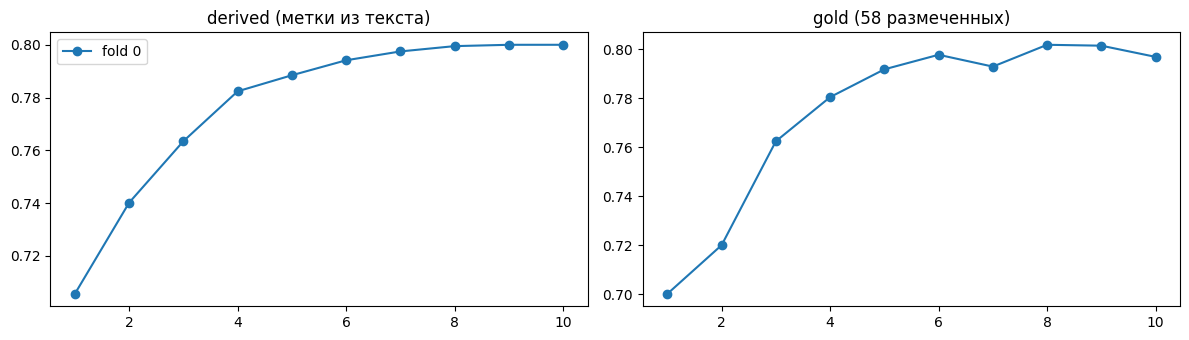

In [29]:
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
HIST, GOLD_PREDS = [], []
for k in FOLDS_TO_RUN:
    t_fold = time.time()
    model, state, gp, hist = train_fold(k)
    HIST += hist
    GOLD_PREDS.append(pd.DataFrame(gp).rank(pct=True).values)
    torch.save({"model": state, "config": {"BACKBONE": BACKBONE, "IMG": IMG, "CROP_MM": CROP_MM,
                "K_WIN": K_WIN, "WIN_BAND": list(WIN_BAND), "FILL_MISSING_SLOTS": FILL_MISSING_SLOTS, "UNFREEZE_LAST": UNFREEZE_LAST,
                "HIDDEN": HIDDEN, "TF_DEPTH": TF_DEPTH}}, WEIGHTS_DIR / f"fold{k}.pth")
    fold_time = time.time() - t_fold
    log(f"фолд {k} готов за {fold_time / 60:.1f} мин -> {WEIGHTS_DIR / f'fold{k}.pth'}")
    del model, state
    gc.collect(); empty_device_cache()

y_gold = Y_GOLD[GOLD_IDX].astype(int)
ens = np.mean(GOLD_PREDS, axis=0)
log(f"ансамбль {len(GOLD_PREDS)} фолд(ов) на {len(GOLD_IDX)} размеченных: gold macro-AUC = {macro_auc(y_gold, ens):.4f}")
per_t = [roc_auc_score(y_gold[:, j], ens[:, j]) if 0 < y_gold[:, j].sum() < len(y_gold) else np.nan
         for j in range(len(TARGETS))]
display(pd.Series(per_t, index=TARGETS, name="gold AUC по целям").round(3).to_frame())

h = pd.DataFrame(HIST)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for f_, gdf in h.groupby("fold"):
    ax[0].plot(gdf.epoch, gdf.derived, "o-", label=f"fold {f_}")
    ax[1].plot(gdf.epoch, gdf.gold, "o-", label=f"fold {f_}")
ax[0].set_title("derived (метки из текста)"); ax[1].set_title("gold (58 размеченных)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 8. Что дальше

### Сабмит

1. Веса лежат в `outputs/weights/fold*.pth`. Загрузите эту папку на Kaggle как датасет
   (Datasets -> New Dataset), например `rsna-knee-folds-vits`.
2. Откройте на Kaggle `04_kaggle_submission.ipynb`, подключите соревнование и этот датасет, включите GPU, нажмите Submit.
   Настройки картинок и модели он прочитает прямо из файлов весов.

### Улучшения по одному за раз

1. **LLM-таблицы меток** (раздел 3.2): потолок модели - это качество меток.
2. **Все фолды:** `FOLDS_TO_RUN = [0, 1, 2, 3]`, ансамбль из 4 моделей, обычно +0.01-0.02.
3. **Второй энкодер в ансамбль:** ViT-B (`BACKBONE = "vit_base_patch14_dinov2.lvd142m"`), веса в отдельную папку.
   Разные архитектуры ошибаются по-разному, а `04_kaggle_submission.ipynb` усредняет ранги всех подключённых весов.
4. **`IMG = 336`** в `03_build_cache_kaggle.ipynb`: тонкие разрывы мениска лучше переживают ресайз, кэш вырастет в 2.25 раза.

**Чего не делать:** вертикальный флип (бедро <-> голень), label smoothing (метки уже мягкие),
`pos_weight` и пороги (AUC от них не зависит).